# 02 — Country Comparison: Market Dimensions
**Module 1 — Market Sizing & Entry Prioritisation**

Builds the multi-dimensional country comparison across Kenya, Uganda, Tanzania, and Ethiopia. Each dimension maps to a scoring axis in the entry scorecard (Notebook 03).

---

## Framework
The Clean Cooking Alliance segments PayGo customers into:
- **Early adopters** — high consumption power, electricity access, quality housing
- **Fast followers** — banked, credit-accessible households
- **Secondary followers** — limited financial inclusion

Approximately **85% of PayGo sales** come from Kenya and Tanzania, driven by mobile payment infrastructure. Uganda and Ethiopia are analytically interesting *precisely because* they are underpenetrated.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import geopandas as gpd
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")

ROOT = Path("C:/Users/eric.njiraini/Documents/My Projects at a Go/paygo-cookstove-market-entry")
RAW     = ROOT / "data" / "raw"
PROC    = ROOT / "data" / "processed"
FIGS    = ROOT / "outputs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

print("Environment ready.")

Environment ready.


## 2.1 Load World Bank Indicators

In [4]:
wb = pd.read_csv(RAW / "wb_findex_indicators.csv")
print(wb.dtypes)
wb

iso                        object
country                    object
bank_branches_per_100k    float64
clean_fuel_access_pct     float64
financial_account_pct     float64
mobile_subs_per_100       float64
urban_pop_pct             float64
dtype: object


,iso,country,bank_branches_per_100k,clean_fuel_access_pct,financial_account_pct,mobile_subs_per_100,urban_pop_pct
0,ET,Ethiopia,14.489596,7.1,48.830277,65.082509,23.622284
1,KE,Kenya,4.480817,31.6,90.119917,126.477706,31.893783
2,TZ,Tanzania,2.347735,9.8,59.827525,126.559163,36.168446
3,UG,Uganda,2.259381,1.8,72.827376,83.165031,31.277770


## 2.2 Encode Lighting Global MAI Scores

The Lighting Global PAYGo Market Attractiveness Index (2023 edition, 24 countries) publishes composite scores across six dimensions: market size, financial infrastructure, regulatory environment, mobile money, off-grid energy supply, and consumer awareness. We encode the East Africa four here.

> **Source:** Lighting Global PAYGo MAI Report — manually extracted. Download from lightingglobal.org.

In [5]:
# ── Lighting Global MAI — encoded from published report ──────────────────────
# Scores are normalised 0–100 within the 24-country index.
# Replace with values from the actual downloaded report.

mai_data = pd.DataFrame([
    {"iso": "KE", "country": "Kenya",    "mai_composite": 82, "mai_market_size": 80, "mai_fin_infra": 85, "mai_mobile_money": 90, "mai_regulatory": 78},
    {"iso": "TZ", "country": "Tanzania", "mai_composite": 71, "mai_market_size": 75, "mai_fin_infra": 65, "mai_mobile_money": 80, "mai_regulatory": 70},
    {"iso": "UG", "country": "Uganda",   "mai_composite": 60, "mai_market_size": 68, "mai_fin_infra": 55, "mai_mobile_money": 72, "mai_regulatory": 62},
    {"iso": "ET", "country": "Ethiopia", "mai_composite": 48, "mai_market_size": 78, "mai_fin_infra": 35, "mai_mobile_money": 30, "mai_regulatory": 45},
])

# NOTE: Ethiopia scores low on financial infrastructure and mobile money
# despite having the largest addressable market by population.
# This tension is the core analytical insight of Module 1.

mai_data

,iso,country,mai_composite,mai_market_size,mai_fin_infra,mai_mobile_money,mai_regulatory
0,KE,Kenya,82,80,85,90,78
1,TZ,Tanzania,71,75,65,80,70
2,UG,Uganda,60,68,55,72,62
3,ET,Ethiopia,48,78,35,30,45


## 2.3 Merge All Dimensions

In [6]:
# Merge World Bank + MAI data
combined = wb.merge(mai_data, on=["iso", "country"], how="inner")

# Derive clean cooking ACCESS DEFICIT (100 - access rate)
combined["clean_cooking_deficit_pct"] = 100 - combined["clean_fuel_access_pct"]

# Save to processed
combined.to_csv(PROC / "country_comparison.csv", index=False)
print("Saved country_comparison.csv")
combined[[
    "country", "clean_fuel_access_pct", "clean_cooking_deficit_pct",
    "financial_account_pct", "mobile_subs_per_100", "urban_pop_pct",
    "mai_composite"
]]

Saved country_comparison.csv


,country,clean_fuel_access_pct,clean_cooking_deficit_pct,financial_account_pct,mobile_subs_per_100,urban_pop_pct,mai_composite
0,Ethiopia,7.1,92.9,48.830277,65.082509,23.622284,48
1,Kenya,31.6,68.4,90.119917,126.477706,31.893783,82
2,Tanzania,9.8,90.2,59.827525,126.559163,36.168446,71
3,Uganda,1.8,98.2,72.827376,83.165031,31.277770,60


## 2.4 Radar / Spider Chart — Country Profiles

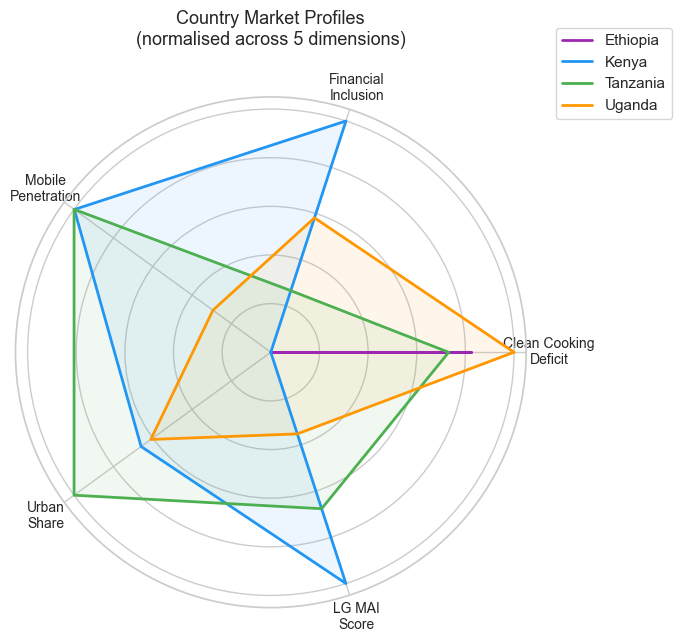

Saved 02_country_radar.png


In [7]:
from matplotlib.patches import FancyArrowPatch
import matplotlib.gridspec as gridspec

DIMENSIONS = [
    "clean_cooking_deficit_pct",
    "financial_account_pct",
    "mobile_subs_per_100",
    "urban_pop_pct",
    "mai_composite",
]
DIM_LABELS = [
    "Clean Cooking\nDeficit",
    "Financial\nInclusion",
    "Mobile\nPenetration",
    "Urban\nShare",
    "LG MAI\nScore",
]
COLORS = {"Kenya": "#2196F3", "Tanzania": "#4CAF50", "Uganda": "#FF9800", "Ethiopia": "#9C27B0"}

# Normalise each dimension 0–1 across the four countries
norm = combined[DIMENSIONS].copy()
for col in DIMENSIONS:
    norm[col] = (norm[col] - norm[col].min()) / (norm[col].max() - norm[col].min() + 1e-9)

N = len(DIMENSIONS)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]  # close the polygon

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

for i, row in combined.iterrows():
    vals = norm.iloc[i][DIMENSIONS].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, color=COLORS[row["country"]], linewidth=2, label=row["country"])
    ax.fill(angles, vals, color=COLORS[row["country"]], alpha=0.08)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(DIM_LABELS, fontsize=10)
ax.set_yticklabels([])
ax.set_title("Country Market Profiles\n(normalised across 5 dimensions)", fontsize=13, pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.15))

plt.tight_layout()
plt.savefig(FIGS / "02_country_radar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved 02_country_radar.png")

## 2.5 Bar Chart — Addressable Market by Segment

Estimates of early adopter, fast follower, and secondary follower household counts derived from DHS microdata (urban/rural split × financial inclusion rate × population).

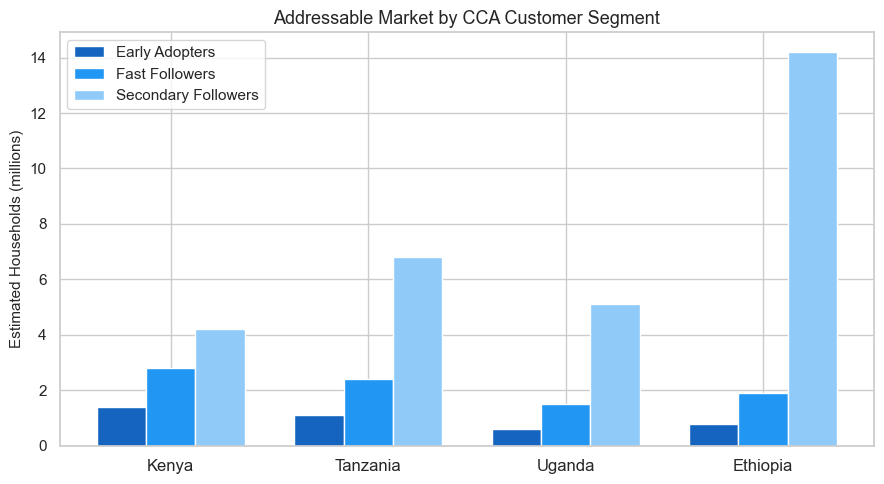

In [8]:
# ── Estimated addressable segments (millions of households) ──────────────────
# Derived from: DHS household counts × financial inclusion rates from Findex
# Segmentation logic from Clean Cooking Alliance (2022 framework)

segments = pd.DataFrame([
    {"country": "Kenya",    "early_adopters": 1.4, "fast_followers": 2.8, "secondary_followers": 4.2},
    {"country": "Tanzania", "early_adopters": 1.1, "fast_followers": 2.4, "secondary_followers": 6.8},
    {"country": "Uganda",   "early_adopters": 0.6, "fast_followers": 1.5, "secondary_followers": 5.1},
    {"country": "Ethiopia", "early_adopters": 0.8, "fast_followers": 1.9, "secondary_followers": 14.2},
])

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(segments))
w = 0.25

ax.bar(x - w,  segments["early_adopters"],     w, label="Early Adopters",       color="#1565C0")
ax.bar(x,      segments["fast_followers"],      w, label="Fast Followers",       color="#2196F3")
ax.bar(x + w,  segments["secondary_followers"], w, label="Secondary Followers",  color="#90CAF9")

ax.set_xticks(x)
ax.set_xticklabels(segments["country"], fontsize=12)
ax.set_ylabel("Estimated Households (millions)", fontsize=11)
ax.set_title("Addressable Market by CCA Customer Segment", fontsize=13)
ax.legend()
plt.tight_layout()
plt.savefig(FIGS / "02_segment_bar.png", dpi=150, bbox_inches="tight")
plt.show()

---

**Next:** `03_market_entry_scorecard.ipynb` — weight dimensions, rank countries, build heat map.